In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import SGDRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_excel(r"C:\Users\Ibhrahim ansari\Desktop\supervised learning\project 1(house price prediction)\RealEstate_HousePrice_Dataset_4200.xlsx")
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


In [4]:
df.describe()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
count,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4200.000000,4.200000e+03
mean,102100.500000,1667.357381,3.696667,2.827381,5.611429,23.829524,18.186167,3366.329048,0.642381,0.096190,7.955714,2.364189e+07
std,1212.579894,630.336132,1.574199,1.153585,2.140880,13.945663,8.674549,1658.230565,0.479356,0.294887,7.316766,1.239279e+07
min,100001.000000,450.000000,1.000000,1.000000,1.000000,1.000000,1.000000,800.000000,0.000000,0.000000,0.000000,8.000000e+05
25%,101050.750000,1226.750000,3.000000,2.000000,4.000000,13.000000,11.800000,2122.500000,0.000000,0.000000,2.000000,1.425969e+07
50%,102100.500000,1660.000000,4.000000,3.000000,5.700000,21.000000,17.800000,3188.000000,1.000000,0.000000,6.000000,2.214500e+07
75%,103150.250000,2084.250000,5.000000,4.000000,7.300000,32.000000,24.200000,4364.250000,1.000000,0.000000,12.000000,3.096090e+07
max,104200.000000,4202.000000,7.000000,6.000000,10.000000,80.000000,47.600000,12938.000000,1.000000,1.000000,50.000000,7.611172e+07


In [5]:
df.isna().sum()

house_id                0
area_sqft               0
bedrooms                0
bathrooms               0
location_score          0
age_years               0
distance_city_km        0
lot_size_sqft           0
has_garage              0
has_pool                0
renovation_years_ago    0
house_price_inr         0
dtype: int64

### Part C :- Simple linear regression

In [6]:
X_simple = df[['area_sqft']]
y = df['house_price_inr']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple,
    y,
    test_size=0.3,
    random_state=42
)

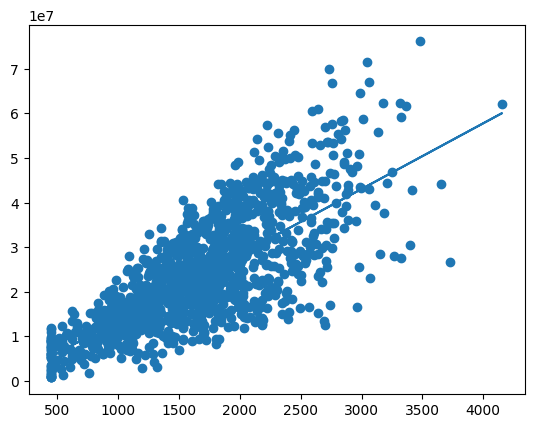

In [7]:
model_simple = LinearRegression()

model_simple.fit(X_train_s, y_train_s)

y_pred_simple = model_simple.predict(X_test_s)

plt.scatter(X_test_s, y_test_s)

plt.plot(X_test_s, y_pred_simple)

plt.show()

In [8]:
mae = mean_absolute_error(
    y_test_s,
    y_pred_simple
)

mse = mean_squared_error(
    y_test_s,
    y_pred_simple
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_s,
    y_pred_simple
)

print("MAE =", mae)
print("MSE =", mse)
print("RMSE =", rmse)
print("R2 =", r2)

MAE = 6341919.212821871
MSE = 67312934455128.94
RMSE = 8204446.017564436
R2 = 0.5679404212239498


In [9]:
X = df.drop(["house_id", "house_price_inr"], axis = 1)
y = df["house_price_inr"]

In [10]:
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

y_pred_multi = model_multi.predict(X_test_m)

In [11]:
print(
    r2_score(
        y_test_m,
        y_pred_multi
    )
)

0.917760687750989


In [12]:
poly = PolynomialFeatures(
    degree=2
)

X_poly = poly.fit_transform(X)

In [13]:
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_poly,
    y,
    test_size=0.2,
    random_state=42
)

model_poly = LinearRegression()
model_poly.fit(X_train_p, y_train_p)

y_pred_poly = model_poly.predict(X_test_p)

In [14]:
print(
    r2_score(
        y_test_m,
        y_pred_poly
    )
)

0.9664360423421318


In [15]:
sgd = SGDRegressor(
    max_iter=1000
)

sgd.fit(
    X_train_m,
    y_train_m
)

y_pred_sgd = sgd.predict(
    X_test_m
)

In [16]:
print(
"Simple Regression:",
r2_score(
y_test_s,
y_pred_simple
)
)

print(
"Multiple Regression:",
r2_score(
y_test_m,
y_pred_multi
)
)

print(
"Polynomial Regression:",
r2_score(
y_test_p,
y_pred_poly
)
)

Simple Regression: 0.5679404212239498
Multiple Regression: 0.917760687750989
Polynomial Regression: 0.9664360423421318
